In [13]:
import json
import importlib
import genetic_algorithm
from pathlib import Path

# Mereload perubahan module
importlib.reload(genetic_algorithm) # https://www.geeksforgeeks.org/python/importlib-package-in-python/

from genetic_algorithm import encode_state, decode_state, genetic_algorithm, fitness
from visual import plotState
import matplotlib.pyplot as plt

In [14]:
# Membaca file packages.json
# https://www.geeksforgeeks.org/python/read-json-file-using-python/
with open("../data/packages.json") as file:
    packages = json.load(file)

# Membaca file truck.json
with open("../data/truck.json") as file:
    truck = json.load(file)

In [15]:
def saveRun(initial_chromosome_random, best_chromosome, packages, truck, folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    
    initial_state_random = decode_state(initial_chromosome_random, packages)
    out = {"inside": initial_state_random, "outside": [id for id in packages if id not in initial_state_random], "value": fitness(initial_chromosome_random, packages, truck)}
    with open(folder / "initialState.json", "w") as f:
        json.dump(out, f, indent=2)
    plotState(initial_state_random, packages, truck, folder / "initialState.png")

    final_state = decode_state(best_chromosome, packages)
    out = {"inside": final_state, "outside": [id for id in packages if id not in final_state], "value": fitness(best_chromosome, packages, truck)}
    with open(folder / "finalState.json", "w") as f:
        json.dump(out, f, indent=2)
    plotState(final_state, packages, truck, folder / "finalState.png")

    return fitness(best_chromosome, packages, truck)

run 0: final 1955


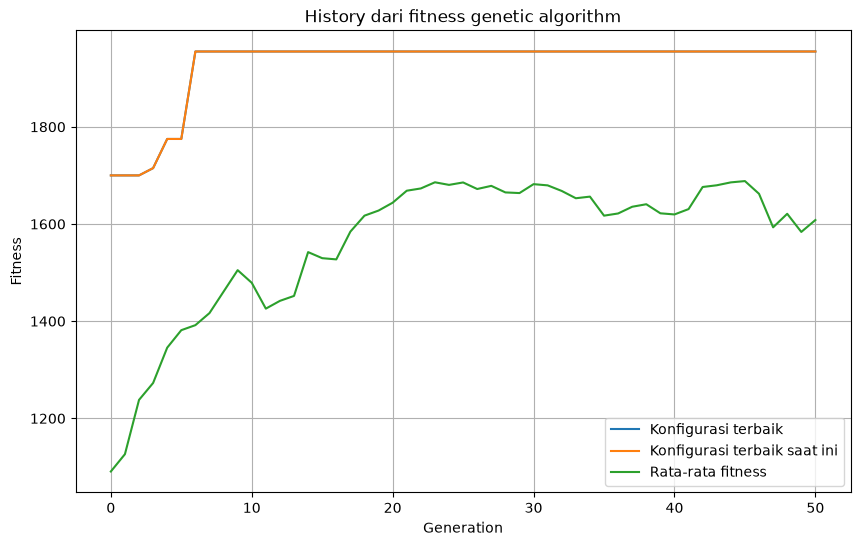

run 1: final 1840


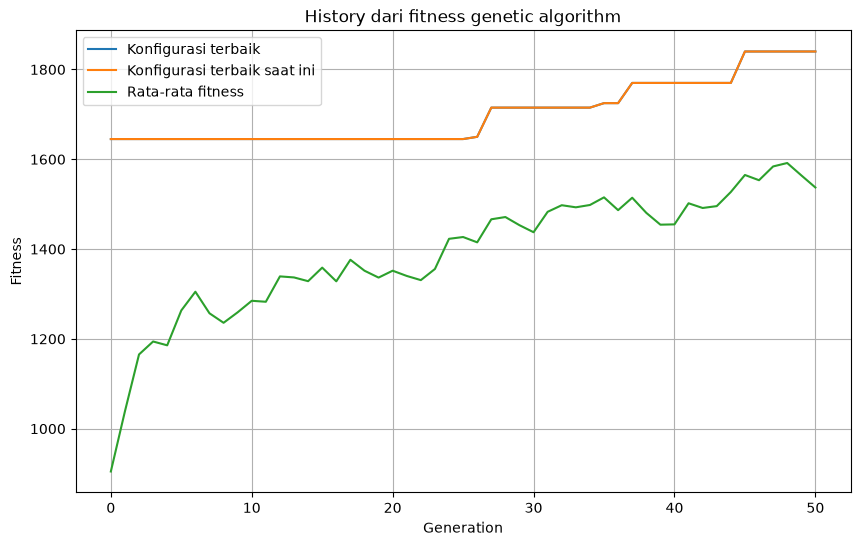

run 2: final 1905


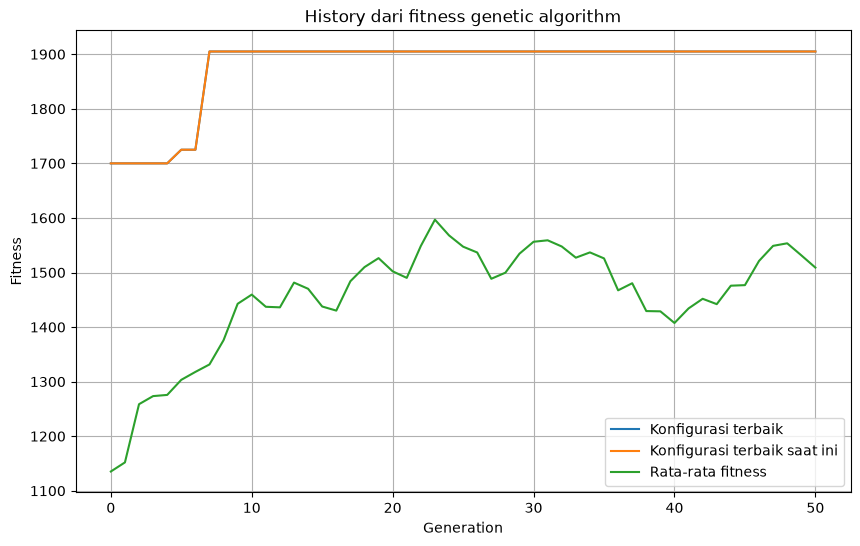

In [16]:
for x in range(3):
    initial_chromosome_random, best_chromosome, history_best, history_curr_best, history_avg = genetic_algorithm(
        packages,
        truck,
        pop_size=30,
        max_iter=50,
        mutation_rate=0.1
    )
    fitness_value = saveRun(initial_chromosome_random, best_chromosome, packages, truck, f"../../output/genetic_algorithm/run{x}")
    print(f"run {x}: final {fitness_value}")

    generations = range(len(history_best)) # Ukuran dari History panjang 

    plt.figure(figsize=(10, 6))

    plt.plot(generations, history_best, label="Konfigurasi terbaik") # Plot konfigurasi terbaik
    plt.plot(generations, history_curr_best, label="Konfigurasi terbaik saat ini") # Plot konfigurasi terbaik saat ini
    plt.plot(generations, history_avg, label="Rata-rata fitness") # Plot rata-rata fitness

    plt.xlabel("Generation")
    plt.ylabel("Fitness")
    plt.title("History dari fitness genetic algorithm")

    plt.legend()
    plt.grid(True)
    plt.show()